# CUSUM-карта по знаковым рангам (CUSUM-SR)

**Непараметрическая карта кумулятивных сумм для медианы процесса в случае
K ($\mu_0$ известно).** Накапливает не сами наблюдения, а статистику
подгруппы, поэтому чувствительна к малым устойчивым сдвигам.

Источник: Chakraborti & Graham (2019), § 4.2.2.4, стр. 206–208; подбор $(k,h)$ —
§ 3.2.2, стр. 67–72. Численные примеры книги (§ 4.3.2) сверяются
автотестами `tests/` и `examples/`.

> Ноутбук запускается из каталога `notebooks/`.

## 1. Импорты и настройка

In [1]:
import sys
sys.path.append('../src')      # запуск из каталога notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from nonparametric_charts.utils import (
    ACCENT,
    VIOLATION,
    WARNING,
    DataLoader,
    DataPreprocessor,
    apply_minimal_latex_style,
    find_iqr_outliers,
    iqr_fences,
    winsorize_outliers,
    summarize_dataset,
)
from nonparametric_charts.charts import (
    CusumSignChart,
    CusumSignedRankChart,
    SignChart,
    SignedRankChart,
)

apply_minimal_latex_style()

from nonparametric_charts.utils import (
    cusum_sign_run_length,
    cusum_signed_rank_run_length,
    design_sign_h,
    design_signed_rank_h,
    design_k_from_shift,
    design_sign_kh,
    design_signed_rank_kh,
    oc_curve,
)

## 2. Теория (минимум)

**Постановка (Case K).** Независимые подгруппы $X_{i1},\ldots,X_{in}$,
целевое значение $\mu_0$ известно; контролируется сдвиг медианы.
Требуется непрерывное **симметричное** распределение: ранги $|X_{ij}-\mu_0|$ должны быть осмысленны.

**Статистика подгруппы** (ур. 4.5, стр. 197; табл. 4.3, стр. 200):

$$SR_i=\sum_{j=1}^{n}\operatorname{sign}(X_{ij}-\mu_0)\,R_{ij}=2T_i^{+}-S,\qquad S=\frac{n(n+1)}{2}$$

**Накопление** (ур. 4.12–4.13, стр. 206):

$$S_i^{+}=\max\{0,\;S_{i-1}^{+}+SR_i-k\},\qquad
S_i^{-}=\min\{0,\;S_{i-1}^{-}+SR_i+k\}.$$

**Сигнал:** $S_i^{+}\ge h$ (сдвиг вверх) или $S_i^{-}\le -h$ (вниз).
Параметры: $k>0$ — референсное значение, $h>0$ — интервал решения.

**Подбор** (§ 3.2.2, стр. 67–72): сначала $k$ (обычно малое или из целевого
сдвига $\delta$, $k\approx E[Z_\delta]/2$), затем $h$ — наибольшее, при
котором $ARL_{IC}\le$ номинала. Для решётчатых $SN$/$SR$ функция
$ARL(h)$ ступенчатая, поэтому номинал достигается только приближённо.

In [2]:
# Те же формулы в виде кода (реализация — в пакете nonparametric_charts):
# SR_i — статистика подгруппы (ур. 4.5, стр. 197; табл. 4.3, стр. 200)
# S+ = max(0, S+ + SR_i − k);  S− = min(0, S− + SR_i + k)
# сигнал: S+ >= h или S− <= −h
# k — первым, h — под ARL_IC <= номинала (§ 3.2.2, стр. 71)

## 3. Загрузка `data.csv`

Строка = подгруппа, столбец = наблюдение; `n` — число столбцов. $\mu_0$
фиксируем по медиане исходных данных, чтобы оба прохода сравнивались при
одном центре.

In [3]:
DATA_PATH = '../data/data.csv'

raw = DataLoader(DATA_PATH).load()
preprocessor = DataPreprocessor(raw)
data, n = preprocessor.get_data_for_chart()

# Целевое значение фиксируем по исходным данным, чтобы оба прохода
# (исходные и очищенные данные) сравнивались при одном μ₀.
MU0 = round(float(np.nanmedian(data.to_numpy(dtype=float))), 3)
FAR0 = 0.0027

print(f'Подгрупп: {len(data)}; наблюдений в подгруппе: n = {n}')
print(f'Целевое значение μ₀ = {MU0:g}; номинальный FAR₀ = {FAR0}')
display(data)

Подгрупп: 10; наблюдений в подгруппе: n = 14
Целевое значение μ₀ = 0.323; номинальный FAR₀ = 0.0027


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,0.152,0.383,0.094,0.067,0.00001,0.316,0.3372,0.811,0.038,0.701,0.137,0.159,0.4571,0.2809
1,0.116,-1.647,0.098,0.642,0.79100,0.988,-0.1760,0.968,0.385,0.361,0.167,0.435,0.9870,0.9940
2,0.322,0.962,0.533,0.798,0.40100,0.838,0.1820,0.632,0.265,0.170,0.783,0.324,0.7710,0.0001
3,0.351,0.829,0.298,-1.892,0.95500,0.688,0.9880,0.477,0.301,0.291,0.565,0.995,0.8890,1.0290
4,0.279,0.003,0.168,22.437,0.87600,-0.127,-0.1370,0.240,0.190,0.289,0.335,0.764,0.2930,0.1120
5,0.239,0.601,0.226,0.986,0.40100,0.158,0.6090,0.093,1.055,0.242,0.251,0.965,0.4920,0.1320
6,0.983,0.785,1.141,4.593,0.45300,0.199,0.5820,0.148,0.402,0.253,0.273,0.381,0.5130,0.3220
7,0.415,0.061,1.823,0.814,0.45100,-0.029,0.7420,0.246,0.332,0.244,0.186,0.944,0.5300,0.3070
8,0.324,0.048,-1.152,-0.072,0.34700,0.714,0.7030,0.226,0.032,0.106,0.164,0.375,0.3070,0.3360
9,0.090,0.168,1.306,0.042,0.28300,0.347,0.5870,0.264,0.029,0.046,0.207,0.153,0.0470,0.1510


## 4. Проверка данных

Пропуски, описательные статистики и выбросы по правилу Тьюки.

In [4]:
summary = summarize_dataset(data)
display(summary.to_frame())

print('Описательные статистики по столбцам:')
display(data.describe().round(3).T)

,значение
подгрупп,10.000000
наблюдений в подгруппе (n),14.000000
ячеек всего,140.000000
пропусков,0.000000
минимум,-1.892000
Q1,0.162750
медиана,0.323000
Q3,0.691250
максимум,22.437000
среднее,0.565938


Описательные статистики по столбцам:


,count,mean,std,min,25%,50%,75%,max
x1,10.0,0.327,0.254,0.090,0.174,0.300,0.344,0.983
x2,10.0,0.219,0.746,-1.647,0.051,0.276,0.739,0.962
x3,10.0,0.454,0.821,-1.152,0.116,0.262,0.989,1.823
x4,10.0,2.842,7.071,-1.892,0.048,0.720,0.943,22.437
x5,10.0,0.496,0.294,0.000,0.360,0.426,0.706,0.955
x6,10.0,0.409,0.378,-0.127,0.168,0.332,0.708,0.988
x7,10.0,0.442,0.383,-0.176,0.221,0.584,0.680,0.988
x8,10.0,0.410,0.299,0.093,0.230,0.255,0.593,0.968
x9,10.0,0.303,0.301,0.029,0.076,0.283,0.372,1.055
x10,10.0,0.270,0.178,0.046,0.188,0.248,0.290,0.701


In [5]:
outliers = find_iqr_outliers(data)
lower, upper, q1, q3 = iqr_fences(data.to_numpy(dtype=float))

print(f'Квартили: Q1 = {q1:.3f}, Q3 = {q3:.3f}')
print(f'IQR-забор: [{lower:.3f}; {upper:.3f}]')
print(f'Выбросов: {len(outliers)} из {data.size} ячеек')
display(outliers)

Квартили: Q1 = 0.163, Q3 = 0.691
IQR-забор: [-0.630; 1.484]
Выбросов: 6 из 140 ячеек


,subgroup,column,value,lower,upper
0,2,x2,-1.647,-0.63,1.484
1,4,x4,-1.892,-0.63,1.484
2,5,x4,22.437,-0.63,1.484
3,7,x4,4.593,-0.63,1.484
4,8,x3,1.823,-0.63,1.484
5,9,x3,-1.152,-0.63,1.484


**Что видно.** 10 подгрупп по 14 наблюдений, пропусков нет. Медиана
$\approx 0.323$, но среднее выше из-за шести выбросов (максимум $22.437$).
Для CUSUM выбросы важны: одна большая статистика подгруппы надолго
сдвигает накопленную сумму.

## 5. Графики данных

In [6]:
def plot_data_overview(frame, title):
    """Гистограмма значений и ящики по подгруппам — проверка данных."""
    values = frame.to_numpy(dtype=float).ravel()
    values = values[~np.isnan(values)]
    found = find_iqr_outliers(frame)
    lower, upper, _, _ = iqr_fences(values)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].hist(values, bins=15, color=ACCENT, alpha=0.75,
                 edgecolor='white')
    axes[0].axvline(MU0, color=VIOLATION, linestyle='--',
                    label=r'$\mu_0$')
    axes[0].axvline(lower, color=WARNING, linestyle=':', label='забор IQR')
    axes[0].axvline(upper, color=WARNING, linestyle=':')
    if len(found):
        axes[0].scatter(
            found['value'],
            np.full(len(found), axes[0].get_ylim()[1] * 0.06),
            color=VIOLATION, zorder=5, label='выбросы',
        )
    axes[0].set_xlabel('Значение')
    axes[0].set_ylabel('Частота')
    axes[0].set_title('Распределение всех наблюдений')
    axes[0].legend()

    axes[1].boxplot(
        [frame.iloc[i].dropna().to_numpy(dtype=float)
         for i in range(len(frame))],
        tick_labels=[str(i + 1) for i in range(len(frame))],
        medianprops={'color': ACCENT},
    )
    axes[1].axhline(MU0, color=VIOLATION, linestyle='--')
    axes[1].set_xlabel('Номер подгруппы')
    axes[1].set_ylabel('Значение')
    axes[1].set_title('Подгруппы')

    fig.suptitle(title)
    plt.tight_layout()
    return fig, axes

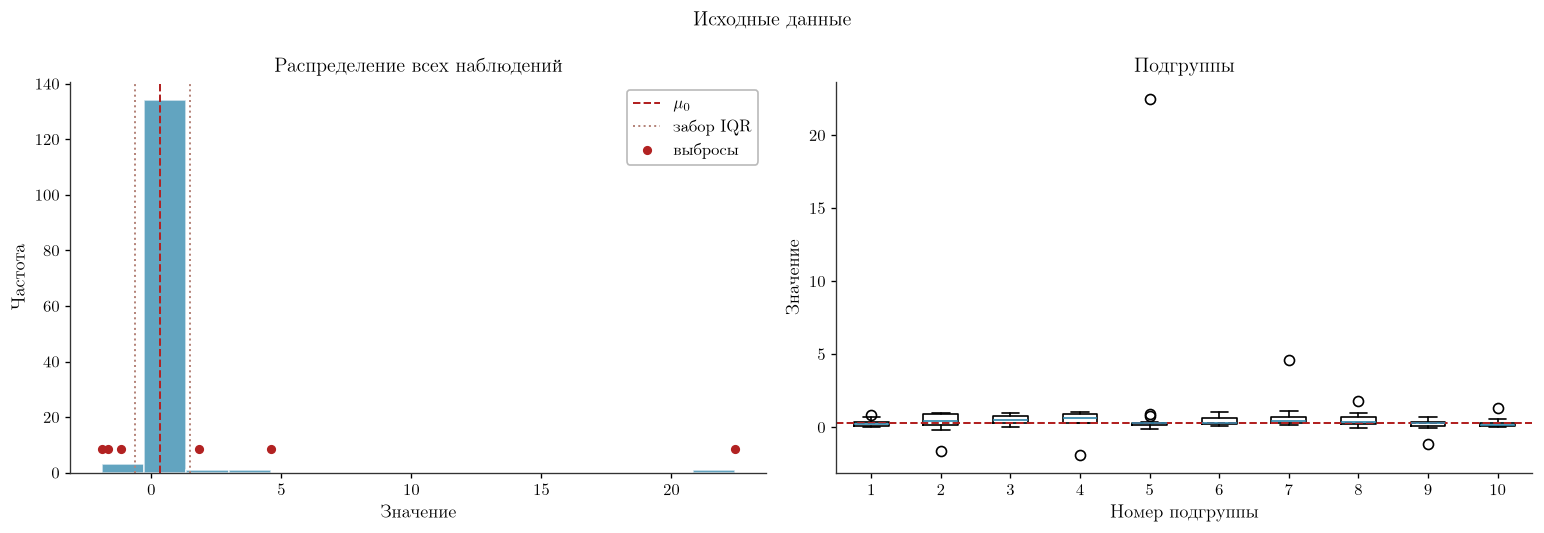

In [7]:
fig, axes = plot_data_overview(data, 'Исходные данные')
plt.show()

**Комментарий.** Основная масса значений лежит около нуля, отдельные
выбросы — в столбцах `x2`, `x3`, `x4`. На ящиках видно, что подгруппы
различаются в основном за счёт этих точек; медианы подгрупп при этом
довольно стабильны.

## 6. Подбор параметров разными методами

### 6.1. Методы подбора

Сравниваем три рецепта:

| Рецепт | Что фиксируем | Что подбираем |
|---|---|---|
| книжный | $k$ из книги | $h$ под $ARL_{IC}\le$ номинала |
| по сдвигу | $k\approx E[Z_\delta]/2$ для $\delta=1.5$ | $h$ под $ARL_{IC}\le$ номинала |
| совместный | сетку $k$ | $(k,h)$ с минимальным $ARL_{OOC}$ |

Считаем всё функциями дизайна из пакета; в ячейках нет собственного
перебора.

In [8]:
TARGET_ARL = 500.0
DELTA = 1.5
K_BOOK = 41.0

# Как в реальной задаче: k — из целевого сдвига (аналог k = δ/2),
# привязанное к решётке статистики; h — под номинал ARL_IC.
design_shift = design_k_from_shift(
    n, TARGET_ARL, DELTA, statistic='SR', tol=0.10,
)
K_REF = design_shift.k
k_star = design_shift.k_star
k_nodes = ', '.join(f'{value:g}' for value in design_shift.candidates)

print(f'k* = E[SR_δ]/2 = {k_star:.3f} → k = {K_REF:g} '
      f'(шаг решётки d = {design_shift.lattice_step:g}; '
      f'кандидаты: {k_nodes})')
print(f'h = {design_shift.h:g}, ARL_IC = {design_shift.arl:.1f} '
      f'({design_shift.relative_error:+.1%} от номинала)')
print(design_shift.note)

design_book = design_signed_rank_h(n, TARGET_ARL, K_BOOK)
joint = design_signed_rank_kh(
    n, TARGET_ARL, DELTA, k_values=(37, 41, 45, 49, 53), tol=0.15,
)


def arl_at(k, h):
    """ARL при целевом сдвиге δ = DELTA."""
    return float(oc_curve(n, k, h, [DELTA], statistic='SR')['arl'].iloc[0])


design_table = pd.DataFrame([
    {
        'рецепт': f'книжный (k = {K_BOOK:g})',
        'k': K_BOOK,
        'h': design_book.h,
        'ARL_IC': design_book.arl,
        'ARL_OOC': arl_at(K_BOOK, design_book.h),
    },
    {
        'рецепт': f'по сдвигу (k = {K_REF:g})',
        'k': K_REF,
        'h': design_shift.h,
        'ARL_IC': design_shift.arl,
        'ARL_OOC': arl_at(K_REF, design_shift.h),
    },
    {
        'рецепт': 'совместный (k, h)',
        'k': joint.k,
        'h': joint.h,
        'ARL_IC': joint.arl_ic,
        'ARL_OOC': joint.arl_ooc,
    },
])

display(design_table.round(3))

k* = E[SR_δ]/2 = 50.023 → k = 49 (шаг решётки d = 1; кандидаты: 49, 50, 51)
h = 46, ARL_IC = 497.7 (+0.5% от номинала)
Выбран k = 49 — ближайший к k* = 50.023 узел решётки (шаг 1) с ARL_IC в пределах 10% от номинала


,рецепт,k,h,ARL_IC,ARL_OOC
0,книжный (k = 41),41.0,58.0,466.334,1.257
1,по сдвигу (k = 49),49.0,46.0,497.720,1.154
2,"совместный (k, h)",53.0,40.0,442.487,1.114


**Комментарий.** Все три рецепта держат $ARL_{IC}$ около 500. Книжный
($k=41$) даёт $ARL_{OOC}=1.26$, рецепт «по сдвигу» ($k=49$) — $1.15$,
совместный ($k=53$, $h=40$) — $1.11$ при $ARL_{IC}=442$. Здесь совместный
подбор выигрывает: он снижает $ARL_{OOC}$, не выходя за номинал.

### 6.2. Сравнение методов

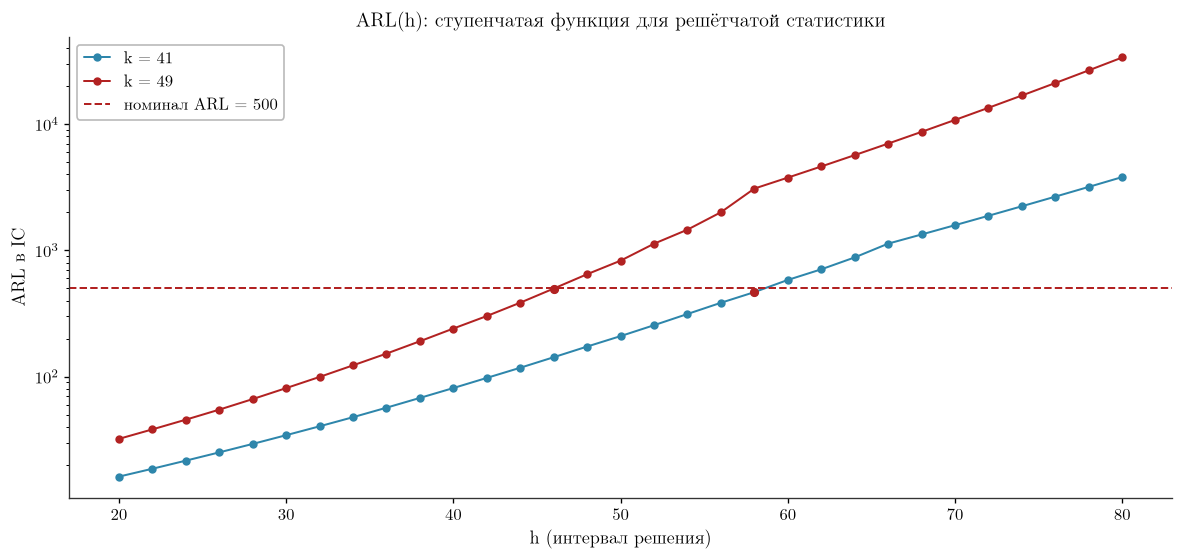

In [9]:
h_grid = np.arange(20, 81, 2)
curves = {
    f'k = {K_BOOK:g}': [cusum_signed_rank_run_length(n, K_BOOK, float(h)).arl
                          for h in h_grid],
    f'k = {K_REF:g}': [cusum_signed_rank_run_length(n, K_REF, float(h)).arl
                         for h in h_grid],
}

fig, ax = plt.subplots(figsize=(10, 4.8))
for label, values in curves.items():
    ax.plot(h_grid, values, 'o-', markersize=4, label=label)
ax.axhline(TARGET_ARL, color=VIOLATION, linestyle='--',
           label=f'номинал ARL = {TARGET_ARL:g}')
ax.scatter([design_book.h], [design_book.arl], color=VIOLATION, zorder=5)
ax.scatter([design_shift.h], [design_shift.arl], color=VIOLATION, zorder=5)
ax.set_yscale('log')
ax.set_xlabel('h (интервал решения)')
ax.set_ylabel('ARL в IC')
ax.set_title('ARL(h): ступенчатая функция для решётчатой статистики')
ax.legend()
plt.tight_layout()
plt.show()

**Комментарий.** Кривые не гладкие: состояния CUSUM лежат на решётке, и
при изменении $h$ между соседними узлами ARL не меняется, а затем
скачком возрастает. Поэтому «попасть» точно в 500 нельзя — книжное правило
и выбирает наибольшее $h$ с $ARL\le$ номинала.

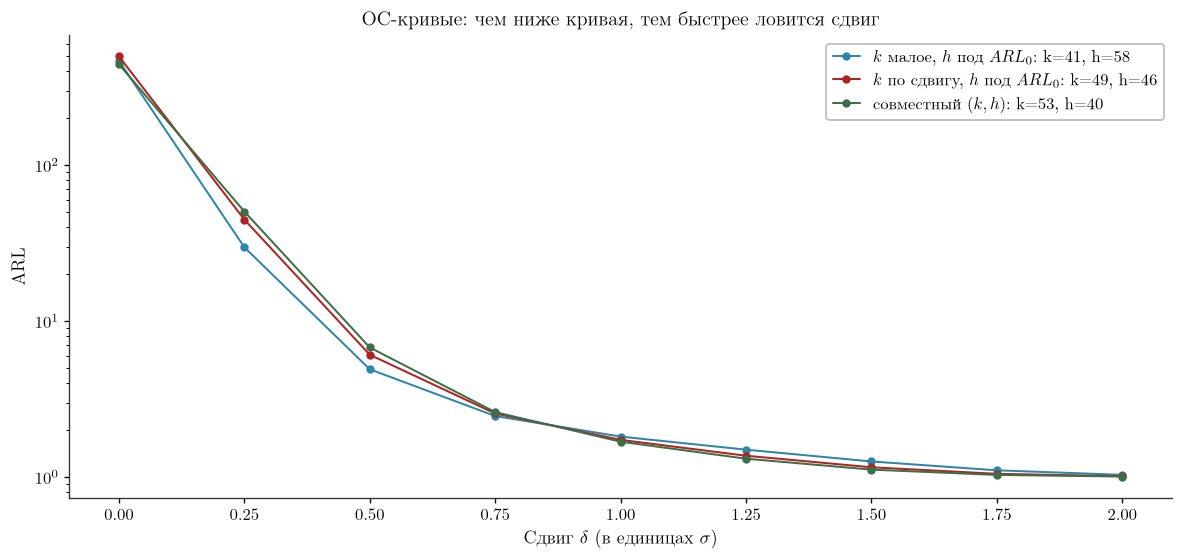

In [10]:
deltas = np.arange(0.0, 2.01, 0.25)
variants = [
    (r'$k$ малое, $h$ под $ARL_0$', K_BOOK, design_book.h),
    (r'$k$ по сдвигу, $h$ под $ARL_0$', K_REF, design_shift.h),
    (r'совместный $(k, h)$', joint.k, joint.h),
]

fig, ax = plt.subplots(figsize=(10, 4.8))
for label, k_value, h_value in variants:
    curve = oc_curve(n, k_value, h_value, deltas, statistic='SR')
    ax.plot(curve['delta'], curve['arl'], 'o-', markersize=4,
            label=f'{label}: k={k_value:g}, h={h_value:g}')

ax.set_yscale('log')
ax.set_xlabel(r'Сдвиг $\delta$ (в единицах $\sigma$)')
ax.set_ylabel('ARL')
ax.set_title('OC-кривые: чем ниже кривая, тем быстрее ловится сдвиг')
ax.legend()
plt.tight_layout()
plt.show()

**Комментарий.** В IC ($\delta=0$) все варианты дают ARL около номинала.
В OOC кривые расходятся: вариант «по сдвигу» быстрее всего реагирует на
$\delta\approx 1.5$, книжный — на меньшие сдвиги, совместный занимает
промежуточное положение. Выбор зависит от того, какой сдвиг важнее ловить,
а не от того, какой вариант «лучше вообще».

## 7. Построение карты

Для карты берём рецепт «по сдвигу»: $k=K_{REF}$, $h$ из таблицы. Такой
выбор соответствует целевому сдвигу $\delta=1.5$ и строгому
$ARL_{IC}\le 500$.

k = 49, h = 46, LCL = -46, UCL = 46
ARL_IC = 497.7 (номинал 500)


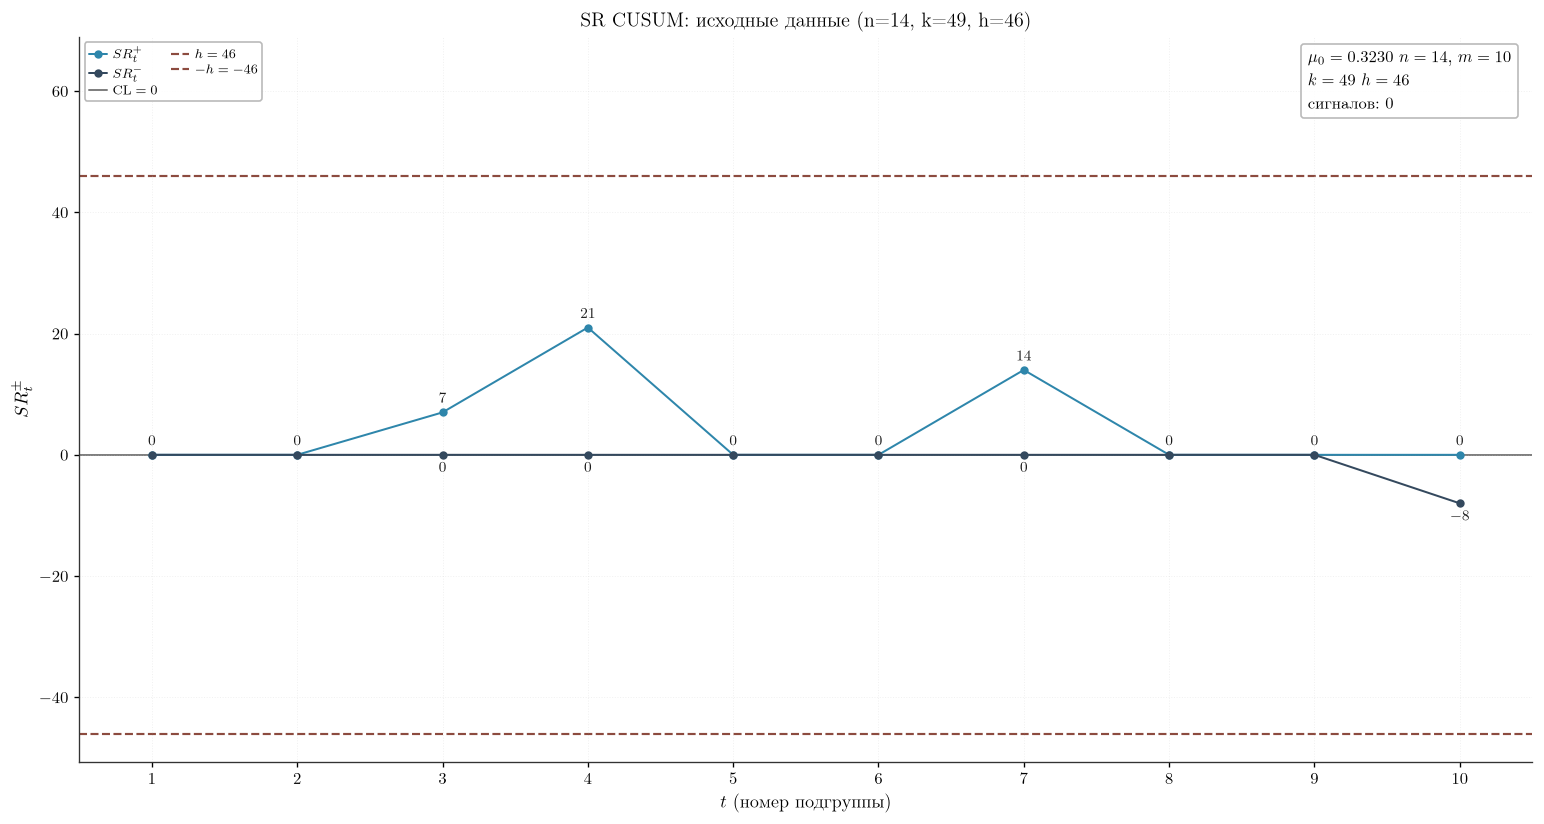

Сигналов: 0


""


In [11]:
chart = CusumSignedRankChart(data, sample_size=n, target_value=MU0,
                    k=K_REF, h=design_shift.h)
limits = chart.calculate_limits()

print(f"k = {limits['k']:g}, h = {limits['h']:g}, "
      f"LCL = {limits['LCL']:g}, UCL = {limits['UCL']:g}")
print(f"ARL_IC = {design_shift.arl:.1f} (номинал {TARGET_ARL:g})")

fig, ax = chart.plot(
    title=f'SR CUSUM: исходные данные (n={n}, k={K_REF:g}, '
          f'h={design_shift.h:g})'
)
plt.show()

violations = pd.DataFrame(chart.violations)
print(f'Сигналов: {len(violations)}')
display(violations if len(violations) else pd.DataFrame())

**Комментарий.** На исходных данных сигналов нет: накопленные суммы
$S^{+}$ и $S^{-}$ не доходят до $\pm h$. CUSUM реагирует не на отдельный
выброс, а на серию подгрупп с одинаковым знаком сдвига — десяти подгрупп
для этого мало.

## 8. Те же шаги на очищенных данных

### 8.1. Очистка выбросов

Выбросы не удаляем, а **винзоризируем**: значения за заборами IQR
заменяем самими заборами. `n=14` и решётка статистики сохраняются,
экстремальные скачки статистики подгруппы ограничены.

In [12]:
data_clean, replaced = winsorize_outliers(data, outliers=outliers)

print(f'Заменено значений: {len(replaced)}; форма сохранена: '
      f'{data_clean.shape == data.shape}')
display(replaced.round(3))

Заменено значений: 6; форма сохранена: True


,subgroup,column,old_value,new_value
0,2,x2,-1.647,-0.630
1,4,x4,-1.892,-0.630
2,5,x4,22.437,1.484
3,7,x4,4.593,1.484
4,8,x3,1.823,1.484
5,9,x3,-1.152,-0.630


### 8.2. Проверка и графики

In [13]:
summary_clean = summarize_dataset(data_clean)
display(summary_clean.to_frame().rename(columns={
    'значение': 'очищенные данные'
}))

,очищенные данные
подгрупп,10.000000
наблюдений в подгруппе (n),14.000000
ячеек всего,140.000000
пропусков,0.000000
минимум,-0.630000
Q1,0.162750
медиана,0.323000
Q3,0.691250
максимум,1.484000
среднее,0.411652


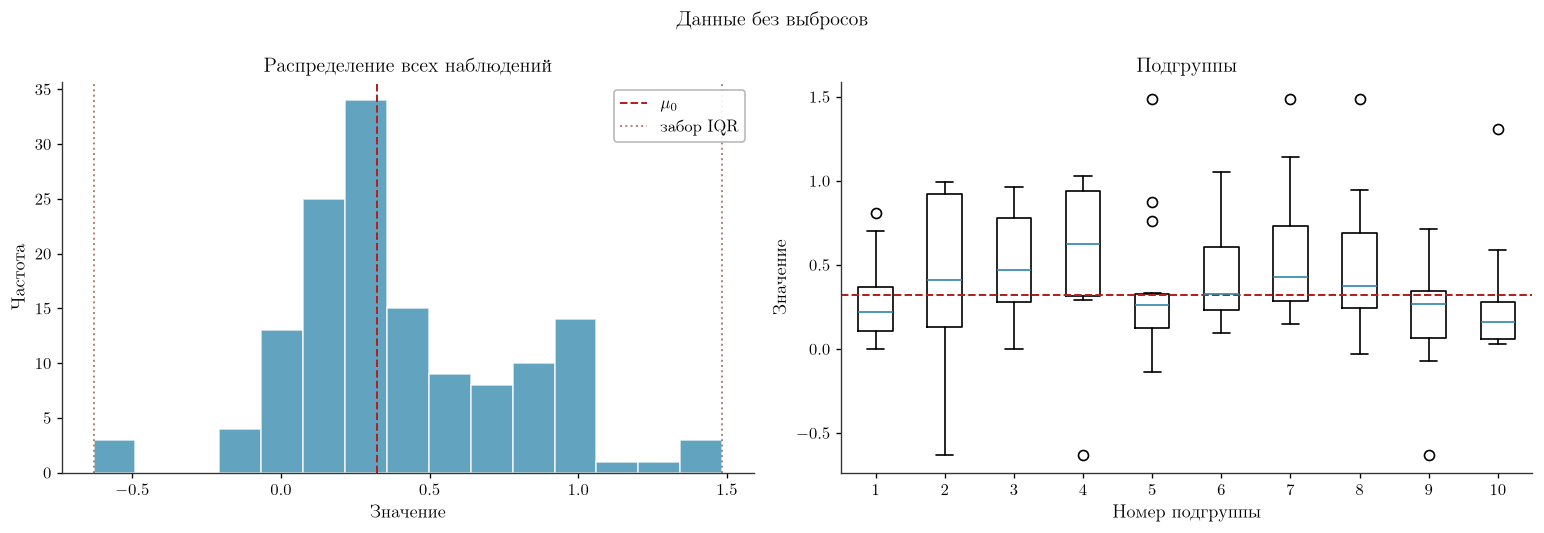

In [14]:
fig, axes = plot_data_overview(data_clean, 'Данные без выбросов')
plt.show()

**Комментарий.** После винзоризации размах стал ровно $[-0.63;\,1.48]$ —
это заборы IQR, а асимметрия упала с $10.4$ до $0.40$. Для CUSUM это
означает, что накопленные суммы больше не «прыгают» из-за одной подгруппы.

### 8.3. Подбор параметров

In [15]:
design_table_clean = design_table.copy()
display(design_table_clean.round(3))

,рецепт,k,h,ARL_IC,ARL_OOC
0,книжный (k = 41),41.0,58.0,466.334,1.257
1,по сдвигу (k = 49),49.0,46.0,497.720,1.154
2,"совместный (k, h)",53.0,40.0,442.487,1.114


**Комментарий.** Таблица не меняется: дизайн $(k,h)$ зависит от `n`,
номинала и целевого сдвига, но не от значений данных. Меняются только
статистики подгрупп и момент сигнала.

### 8.4. Карта на очищенных данных

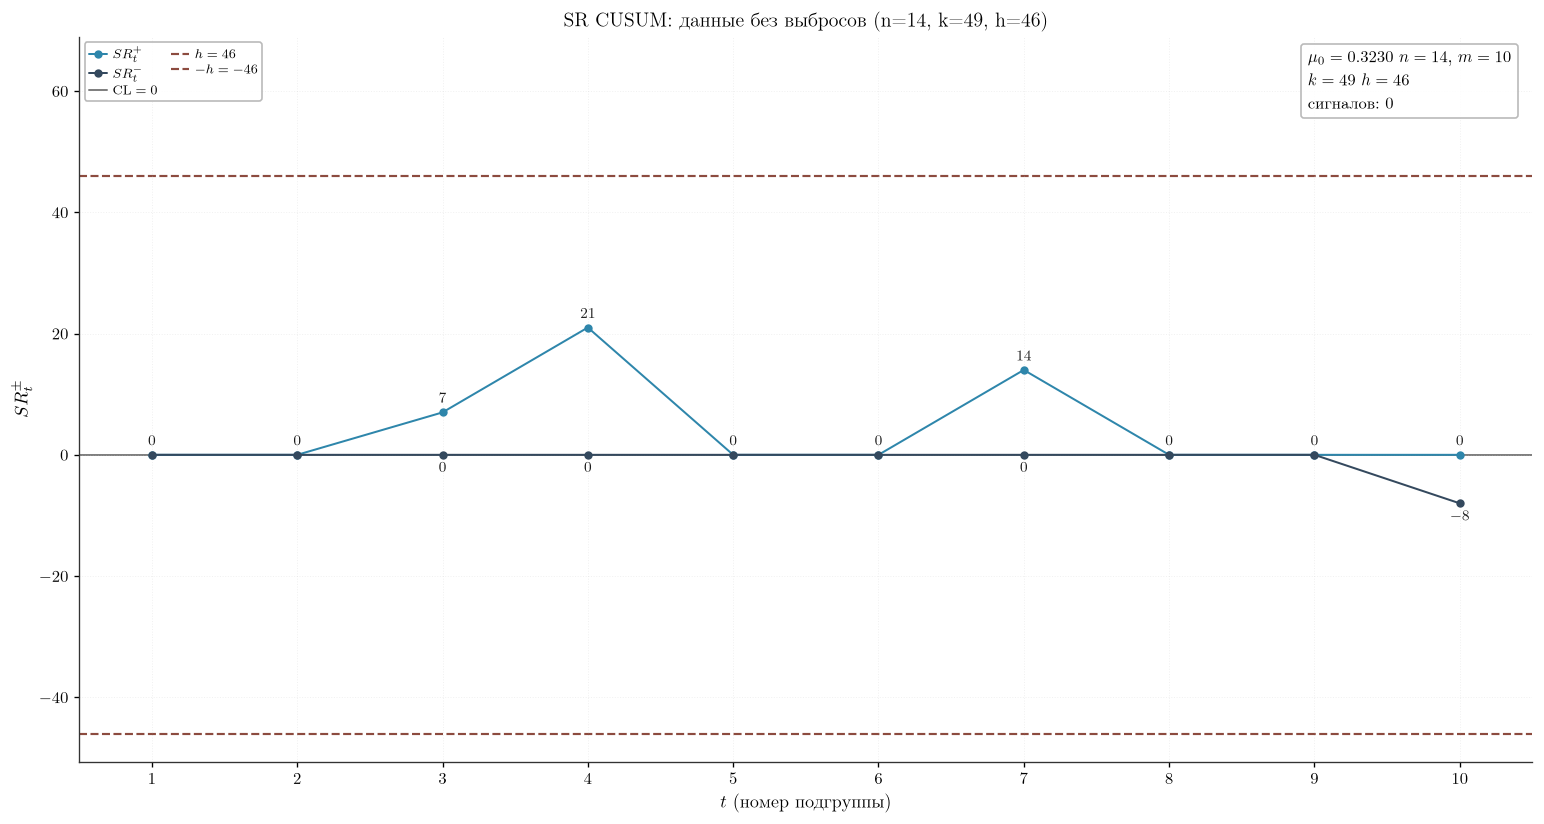

Сигналов: 0


""


In [16]:
chart_clean = CusumSignedRankChart(data_clean, sample_size=n, target_value=MU0,
                       k=K_REF, h=design_shift.h)
chart_clean.calculate_limits()

fig, ax = chart_clean.plot(
    title=f'SR CUSUM: данные без выбросов (n={n}, k={K_REF:g}, '
          f'h={design_shift.h:g})'
)
plt.show()

violations_clean = pd.DataFrame(chart_clean.violations)
print(f'Сигналов: {len(violations_clean)}')
display(violations_clean if len(violations_clean) else pd.DataFrame())

**Комментарий.** После очистки карта ведёт себя спокойнее: без
экстремальных статистик накопленные суммы растут и падают плавно.
Сигналов нет: винзоризация ограничила вклад выбросов, но не сдвинула отрицательные отклонения в положительную область, поэтому накопленные суммы остались в границах.

## 9. Сравнение и итог

In [17]:
rows = []
for name, frame in [('исходные', data), ('без выбросов', data_clean)]:
    current = CusumSignedRankChart(frame, sample_size=n, target_value=MU0,
                        k=K_REF, h=design_shift.h)
    current.calculate_limits()
    rows.append({
        'вариант': name,
        'k': K_REF,
        'h': design_shift.h,
        'ARL_IC': design_shift.arl,
        'сигналов': len(current.violations),
        'первая тревога': (
            current.violations[0]['subgroup']
            if current.violations else '—'
        ),
    })

display(pd.DataFrame(rows).round(3))

,вариант,k,h,ARL_IC,сигналов,первая тревога
0,исходные,49.0,46.0,497.72,0,—
1,без выбросов,49.0,46.0,497.72,0,—


**Выводы.**

1. CUSUM-SN не требует симметрии и работает для любой непрерывной $F$;
   CUSUM-SR мощнее, но требует симметрии.
2. Параметры $(k,h)$ — свойство дизайна, а не данных: они определяются
   размером подгруппы, номиналом $ARL_{IC}$ и целевым сдвигом.
3. Из-за решётчатой статистики $ARL(h)$ ступенчатая, поэтому номинал
   достигается только приближённо; книжное правило даёт $ARL\le$ номинала.
4. Три рецепта подбора дают разные компромиссы; выбирать нужно по тому,
   какой сдвиг важнее обнаруживать.
5. Очистка данных не меняет дизайн, но меняет момент сигнала — поэтому
   проверку данных делают до интерпретации карты.